In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy import signal as scipy_signal
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# GPU check
print(f"PyTorch: {torch.__version__}")
print(f"GPU available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using: {device}")

# ── GLOBAL CONFIG — change only this if your path is different ────────────────
DATASET_PATH      = '/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData'
SAVE_PATH         = '/content/drive/MyDrive/RF_Project/'
TRAIN_DISTANCES   = ['2ft', '8ft', '14ft', '20ft', '26ft']
CHUNKS_PER_FILE   = 50
SAMPLES_PER_CHUNK = 4096
SEQ_LEN_LSTM      = 256
BATCH_SIZE        = 64
NUM_EPOCHS        = 50

os.makedirs(SAVE_PATH, exist_ok=True)

# Verify dataset path
if os.path.exists(DATASET_PATH):
    folders = sorted(os.listdir(DATASET_PATH))
    print(f"\nDataset found! Folders: {folders}")
else:
    print(f"\nERROR: Dataset not found at {DATASET_PATH}")
    print("Fix the DATASET_PATH above")

Mounted at /content/drive
PyTorch: 2.10.0+cu128
GPU available: True
GPU: Tesla T4
Using: cuda

Dataset found! Folders: ['14ft', '20ft', '26ft', '2ft', '32ft', '38ft', '44ft', '50ft', '56ft', '62ft', '8ft']


In [ ]:
# ── Normalize IQ ──────────────────────────────────────────────────────────────
def normalize_iq(iq):
    i_norm = (iq.real - iq.real.mean()) / (iq.real.std() + 1e-8)
    q_norm = (iq.imag - iq.imag.mean()) / (iq.imag.std() + 1e-8)
    return i_norm + 1j * q_norm

# ── IQ → Spectrogram ──────────────────────────────────────────────────────────
def iq_to_spectrogram(iq_complex):
    """Convert complex IQ (4096 samples) → normalized spectrogram (256, 63)."""
    _, _, Sxx = scipy_signal.spectrogram(
        iq_complex,
        fs              = 5e6,
        nperseg         = 128,
        noverlap        = 64,
        nfft            = 256,
        return_onesided = False
    )
    Sxx_db = 10 * np.log10(np.abs(Sxx) + 1e-10)
    mean_v = Sxx_db.mean()
    std_v  = Sxx_db.std() + 1e-8
    return ((Sxx_db - mean_v) / std_v).astype(np.float32)

# ── PyTorch Dataset ───────────────────────────────────────────────────────────
class RFDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

print("Helper functions defined.")

Helper functions defined.


In [ ]:
# LSTM gets the FULL 4096-sample chunk, not just 256
# This is critical for LSTM to learn hardware fingerprints properly
SEQ_LEN_LSTM = 4096   # was 256, now full chunk

def load_all_data(dataset_path, distances,
                  chunks_per_file=50,
                  samples_per_chunk=4096,
                  seq_len=4096):

    device_ids_set = set()
    for dist in distances:
        dp = os.path.join(dataset_path, dist)
        if not os.path.isdir(dp):
            continue
        for f in os.listdir(dp):
            if f.endswith('.sigmf-data'):
                device_ids_set.add(f.split('_')[3])

    device_ids_lst = sorted(list(device_ids_set))
    dev_to_lbl     = {d: i for i, d in enumerate(device_ids_lst)}

    X_cnn, X_lstm, X_raw_iq, y_all = [], [], [], []

    for dist in distances:
        dist_path = os.path.join(dataset_path, dist)
        if not os.path.isdir(dist_path):
            print(f"  Skipping {dist} — not found")
            continue

        files = sorted([f for f in os.listdir(dist_path)
                        if f.endswith('.sigmf-data')])
        print(f"\n── {dist} ({len(files)} files) ──")

        for filename in files:
            dev_id   = filename.split('_')[3]
            label    = dev_to_lbl[dev_id]
            filepath = os.path.join(dist_path, filename)

            raw_iq      = np.fromfile(filepath, dtype=np.complex128)
            raw_iq_norm = normalize_iq(raw_iq)

            count = 0
            for i in range(chunks_per_file):
                start = i * samples_per_chunk
                end   = start + samples_per_chunk
                if end > len(raw_iq_norm):
                    break

                chunk = raw_iq_norm[start:end]  # (4096,) complex

                # CNN: spectrogram (256, 63)
                X_cnn.append(iq_to_spectrogram(chunk))

                # LSTM: FULL chunk as (4096, 2) float
                # IMPORTANT: full chunk, not truncated
                X_lstm.append(
                    np.stack([chunk.real,
                              chunk.imag], axis=1).astype(np.float32)
                )

                # Raw IQ: store for SNR robustness experiment
                # This is the same chunk in complex form
                X_raw_iq.append(chunk.astype(np.complex64))

                y_all.append(label)
                count += 1

            print(f"  {filename[:50]:50s} label={label} chunks={count}")

    X_cnn    = np.array(X_cnn)     # (N, 256, 63)
    X_lstm   = np.array(X_lstm)    # (N, 4096, 2)
    X_raw_iq = np.array(X_raw_iq)  # (N, 4096) complex — for SNR test
    y_all    = np.array(y_all)     # (N,)

    print(f"\n{'='*60}")
    print(f"Total samples : {len(y_all)}")
    print(f"CNN  shape    : {X_cnn.shape}")
    print(f"LSTM shape    : {X_lstm.shape}")
    print(f"Raw IQ shape  : {X_raw_iq.shape}")
    print(f"Devices       : {device_ids_lst}")
    print(f"{'='*60}")

    return X_cnn, X_lstm, X_raw_iq, y_all, device_ids_lst


print("Loading dataset...")

X_cnn_all, X_lstm_all, X_raw_iq_all, y_all, device_ids = load_all_data(
    dataset_path      = DATASET_PATH,
    distances         = TRAIN_DISTANCES,
    chunks_per_file   = CHUNKS_PER_FILE,
    samples_per_chunk = SAMPLES_PER_CHUNK,
    seq_len           = SEQ_LEN_LSTM
)

NUM_CLASSES = len(device_ids)
print(f"\nNUM_CLASSES = {NUM_CLASSES}")
print(f"SEQ_LEN_LSTM = {SEQ_LEN_LSTM} (full 4096-sample chunks)")

Loading dataset...

── 2ft (32 files) ──
  WiFi_air_X310_3123D52_2ft_run1.sigmf-data          label=0 chunks=50
  WiFi_air_X310_3123D52_2ft_run2.sigmf-data          label=0 chunks=50
  WiFi_air_X310_3123D54_2ft_run1.sigmf-data          label=1 chunks=50
  WiFi_air_X310_3123D54_2ft_run2.sigmf-data          label=1 chunks=50
  WiFi_air_X310_3123D58_2ft_run1.sigmf-data          label=2 chunks=50
  WiFi_air_X310_3123D58_2ft_run2.sigmf-data          label=2 chunks=50
  WiFi_air_X310_3123D64_2ft_run1.sigmf-data          label=3 chunks=50
  WiFi_air_X310_3123D64_2ft_run2.sigmf-data          label=3 chunks=50
  WiFi_air_X310_3123D65_2ft_run1.sigmf-data          label=4 chunks=50
  WiFi_air_X310_3123D65_2ft_run2.sigmf-data          label=4 chunks=50
  WiFi_air_X310_3123D70_2ft_run1.sigmf-data          label=5 chunks=50
  WiFi_air_X310_3123D70_2ft_run2.sigmf-data          label=5 chunks=50
  WiFi_air_X310_3123D76_2ft_run1.sigmf-data          label=6 chunks=50
  WiFi_air_X310_3123D76_2ft_run2.sig

✅ Data verified: X_cnn_all=(8000, 256, 63), y_all=(8000,), devices=16

Generating Spectrogram Visualizations...

[1/4] First 8 devices — sample spectrograms...


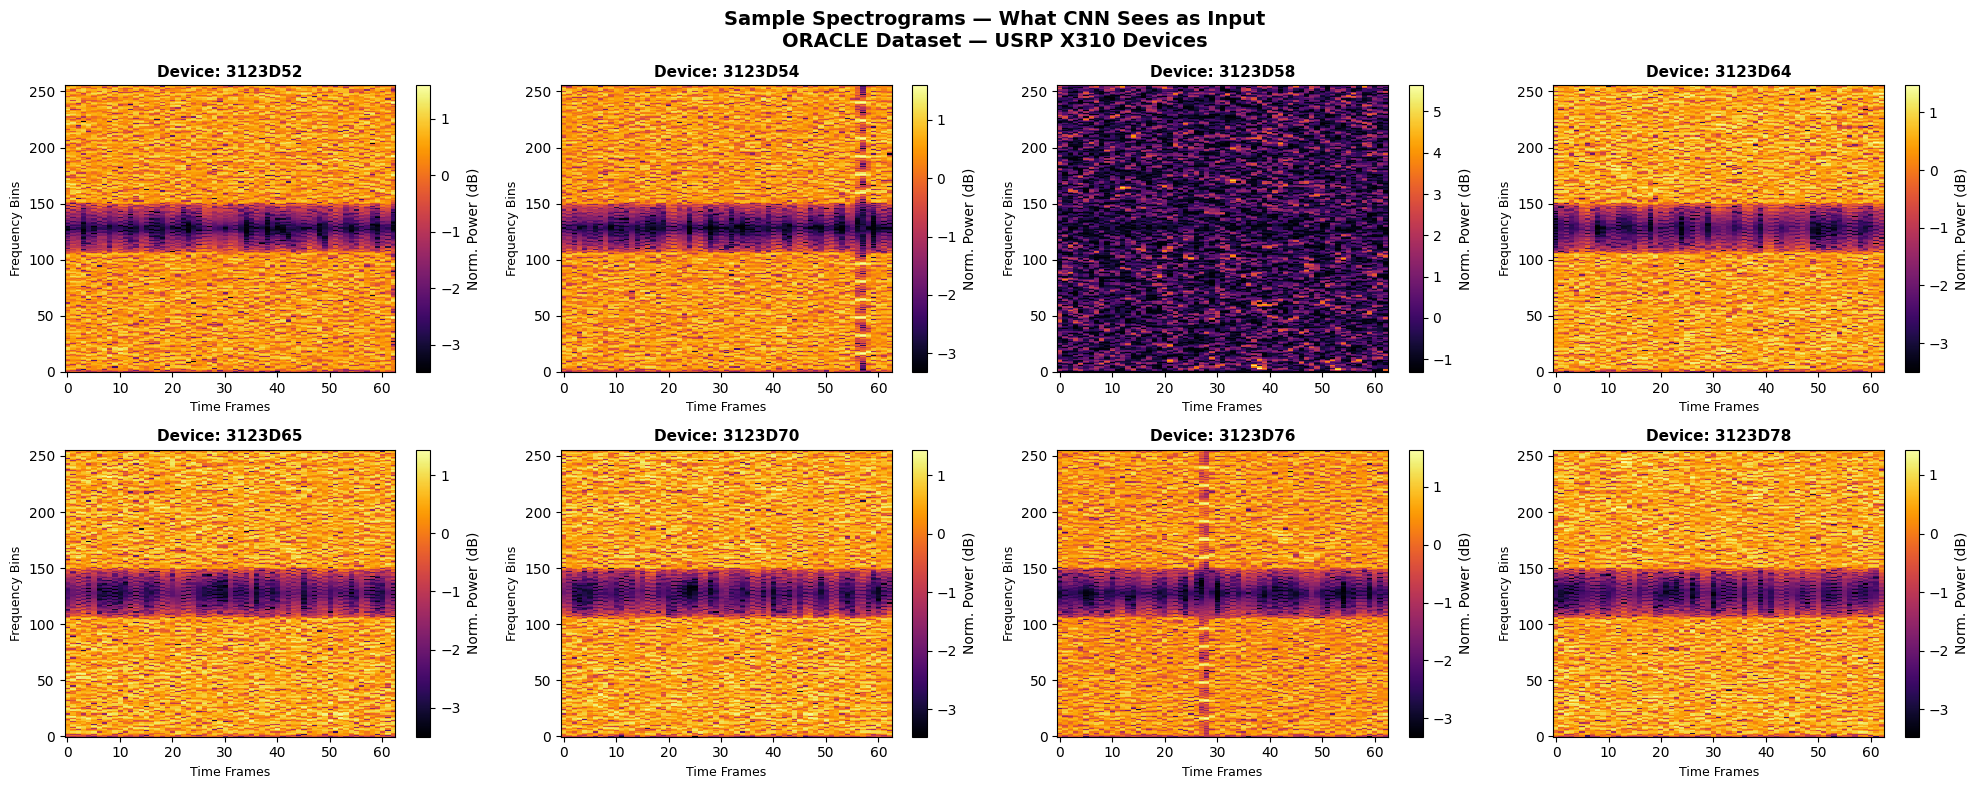

Saved → sample_spectrograms.png

[2/4] All 16 devices — one spectrogram each...


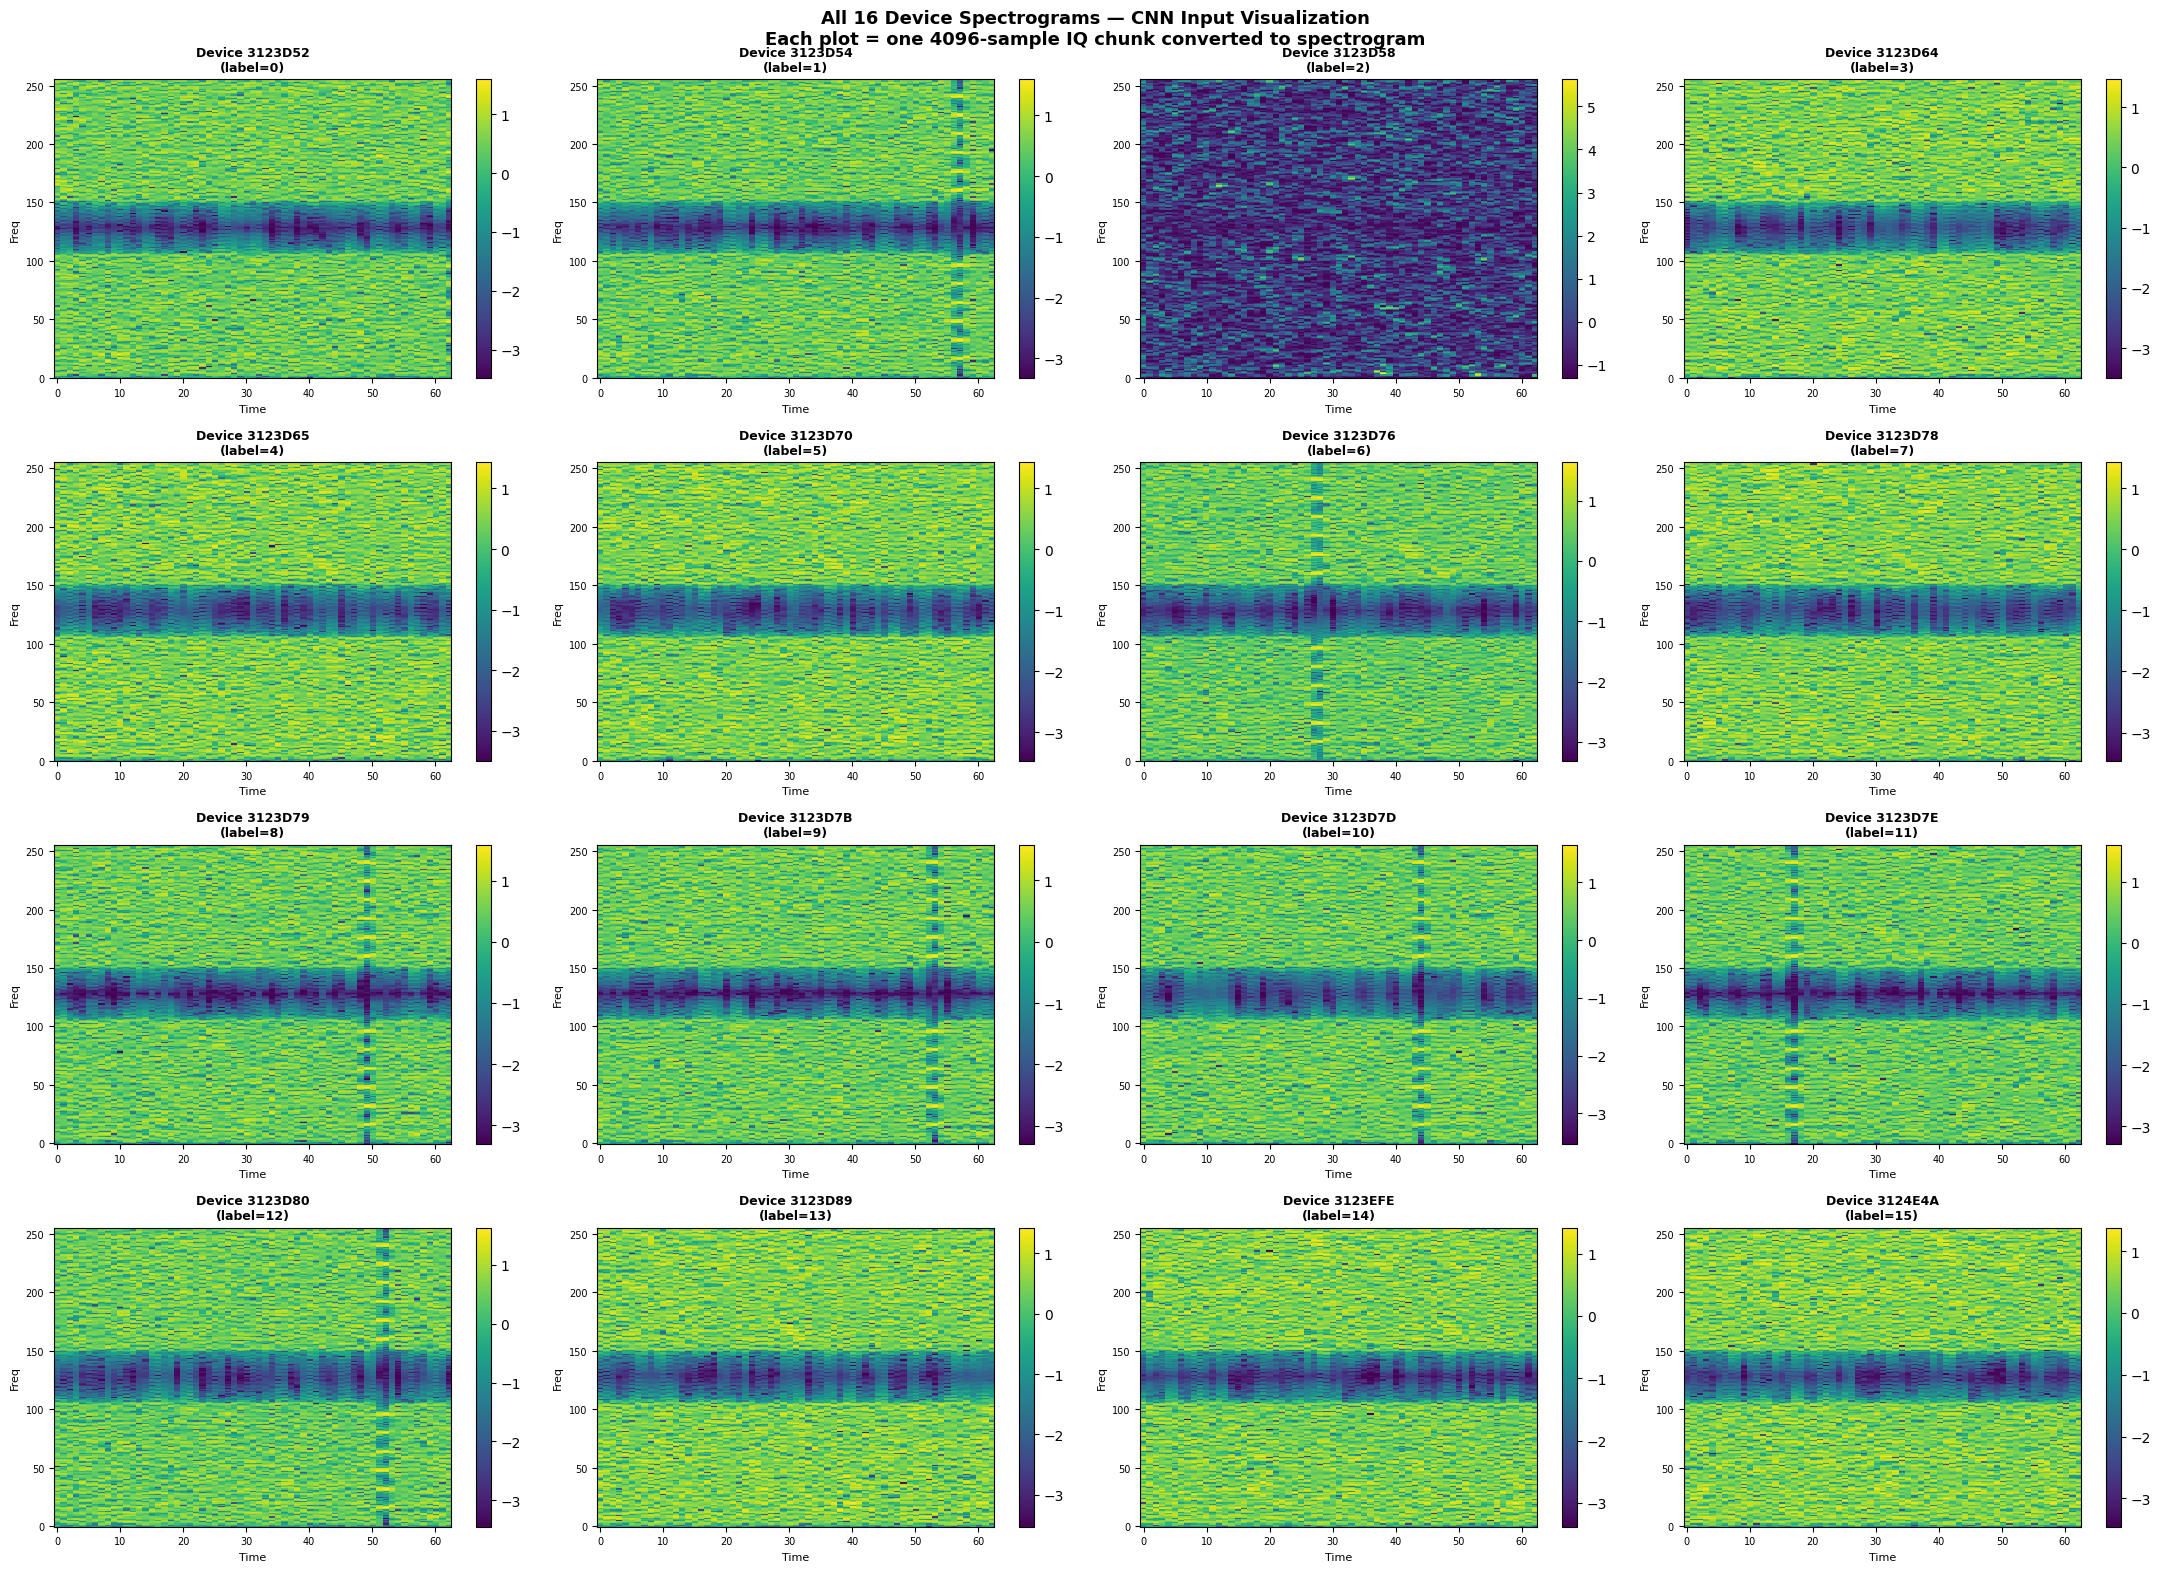

Saved → all_16_spectrograms.png

[3/4] Intra-device variation — device 3123D52...


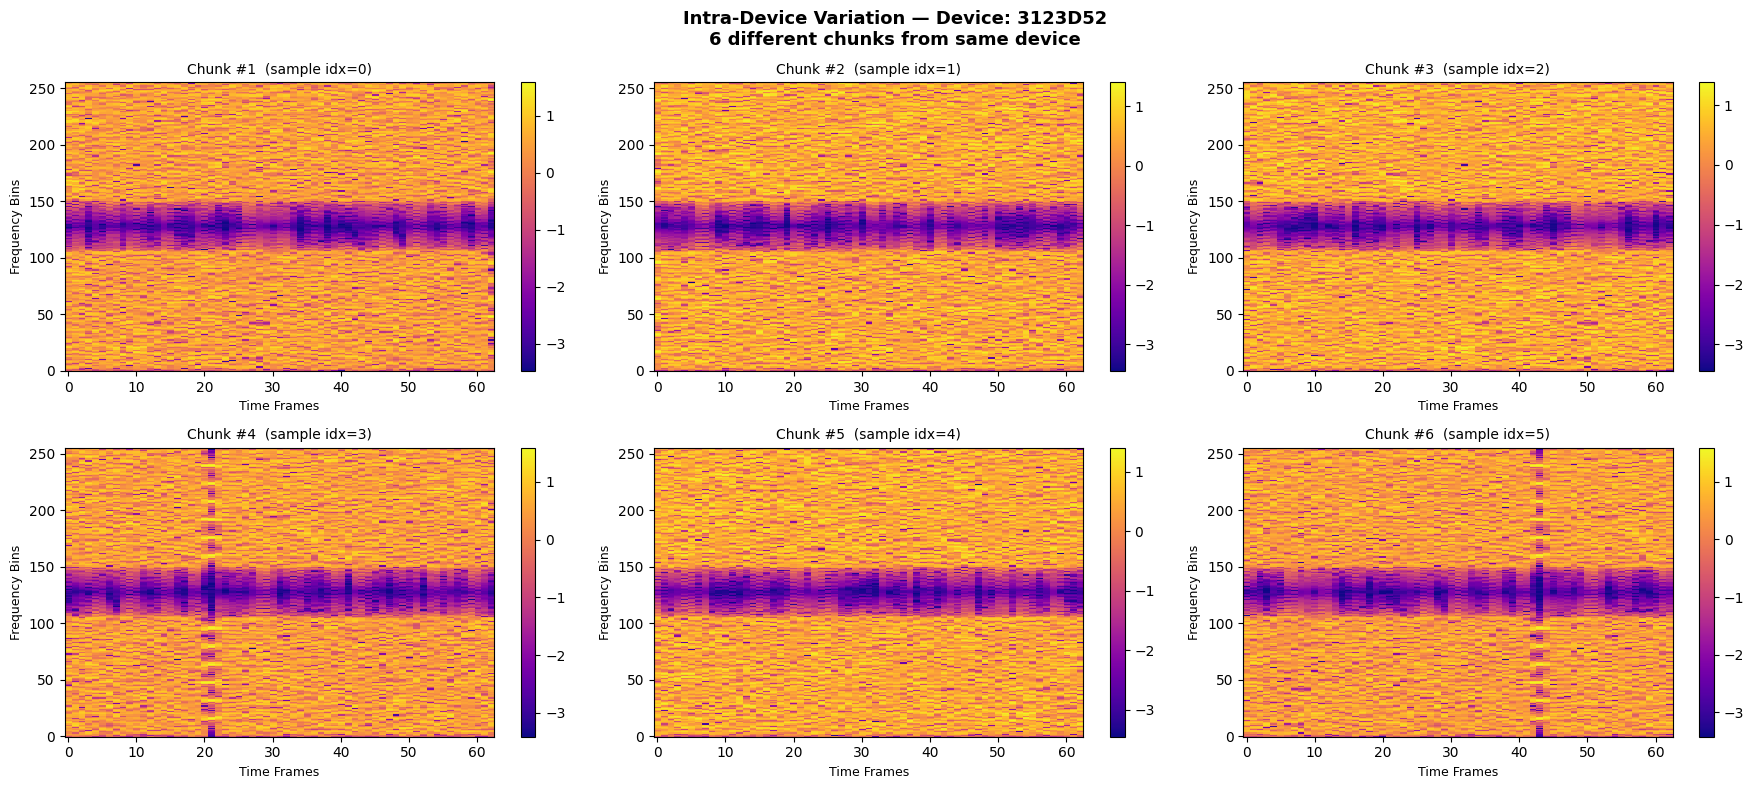

Saved → intra_device_variation.png

[4/4] Inter-device comparison — 3123D52 vs 3123D54...


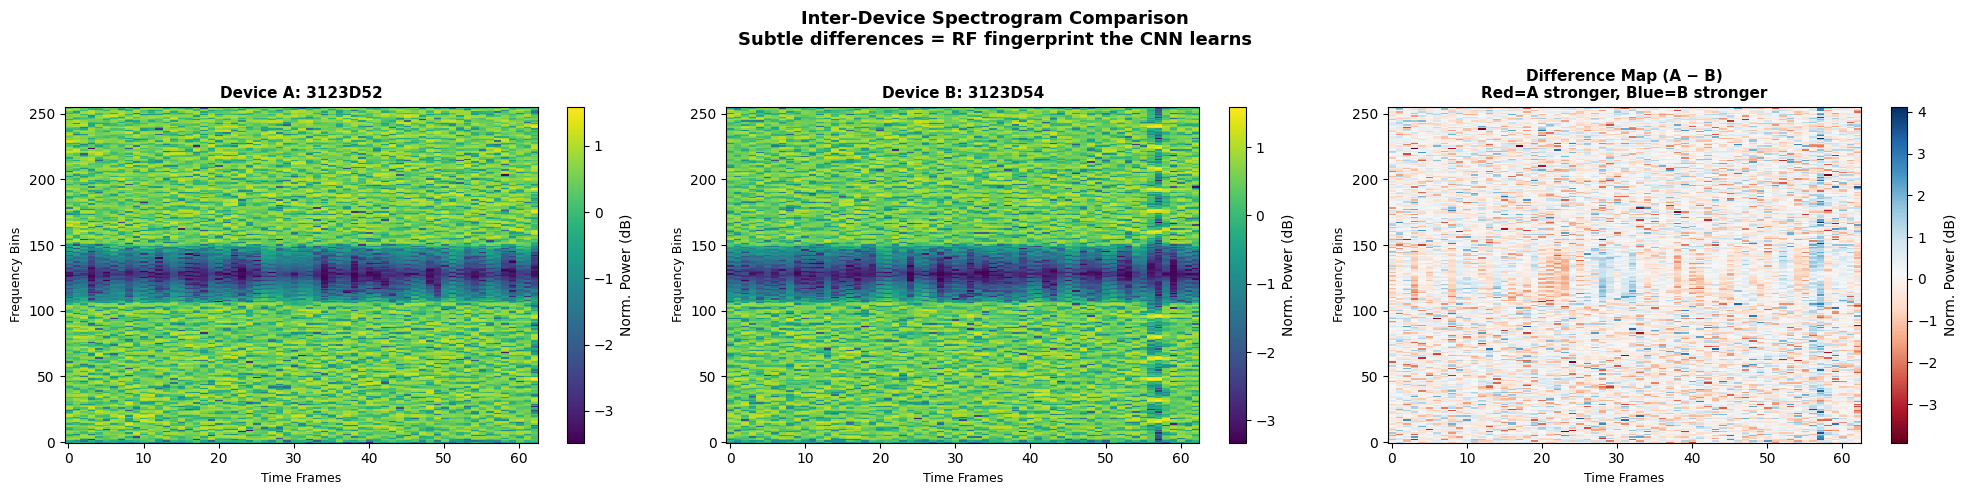

Saved → inter_device_comparison.png

✅ All spectrogram plots saved to: /content/drive/MyDrive/RF_Project/


In [ ]:
def plot_sample_spectrograms(X_cnn_all, y_all, device_ids, n_devices=8):
    fig, axes = plt.subplots(2, 4, figsize=(20, 8))
    fig.suptitle('Sample Spectrograms — What CNN Sees as Input\n'
                 'ORACLE Dataset — USRP X310 Devices',
                 fontsize=14, fontweight='bold')
    axes = axes.flatten()
    for i in range(n_devices):
        idx  = np.where(y_all == i)[0][0]
        spec = X_cnn_all[idx]
        im   = axes[i].imshow(spec, aspect='auto', origin='lower',
                               cmap='inferno', interpolation='nearest')
        axes[i].set_title(f'Device: {device_ids[i]}',
                          fontsize=11, fontweight='bold')
        axes[i].set_xlabel('Time Frames', fontsize=9)
        axes[i].set_ylabel('Frequency Bins', fontsize=9)
        plt.colorbar(im, ax=axes[i], label='Norm. Power (dB)')
    plt.tight_layout()
    plt.savefig(SAVE_PATH + 'sample_spectrograms.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved → sample_spectrograms.png")


def plot_all_spectrograms(X_cnn_all, y_all, device_ids):
    n    = len(device_ids)
    fig, axes = plt.subplots(4, 4, figsize=(22, 16))
    fig.suptitle('All 16 Device Spectrograms — CNN Input Visualization\n'
                 'Each plot = one 4096-sample IQ chunk converted to spectrogram',
                 fontsize=13, fontweight='bold')
    axes = axes.flatten()
    for i in range(n):
        idx  = np.where(y_all == i)[0][0]
        spec = X_cnn_all[idx]
        im   = axes[i].imshow(spec, aspect='auto', origin='lower',
                               cmap='viridis', interpolation='nearest')
        axes[i].set_title(f'Device {device_ids[i]}\n(label={i})',
                          fontsize=9, fontweight='bold')
        axes[i].set_xlabel('Time', fontsize=8)
        axes[i].set_ylabel('Freq', fontsize=8)
        axes[i].tick_params(labelsize=7)
        plt.colorbar(im, ax=axes[i])
    plt.tight_layout()
    plt.savefig(SAVE_PATH + 'all_16_spectrograms.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved → all_16_spectrograms.png")


def plot_intra_device_variation(X_cnn_all, y_all, device_ids,
                                device_idx=0, n_chunks=6):
    fig, axes = plt.subplots(2, 3, figsize=(18, 8))
    fig.suptitle(f'Intra-Device Variation — Device: {device_ids[device_idx]}\n'
                 f'{n_chunks} different chunks from same device',
                 fontsize=13, fontweight='bold')
    axes = axes.flatten()
    idxs = np.where(y_all == device_idx)[0][:n_chunks]
    for plot_i, data_idx in enumerate(idxs):
        spec = X_cnn_all[data_idx]
        im   = axes[plot_i].imshow(spec, aspect='auto', origin='lower',
                                    cmap='plasma', interpolation='nearest')
        axes[plot_i].set_title(f'Chunk #{plot_i+1}  (sample idx={data_idx})',
                                fontsize=10)
        axes[plot_i].set_xlabel('Time Frames', fontsize=9)
        axes[plot_i].set_ylabel('Frequency Bins', fontsize=9)
        plt.colorbar(im, ax=axes[plot_i])
    plt.tight_layout()
    plt.savefig(SAVE_PATH + 'intra_device_variation.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved → intra_device_variation.png")


def plot_inter_device_comparison(X_cnn_all, y_all, device_ids,
                                 dev_a=0, dev_b=1):
    idx_a  = np.where(y_all == dev_a)[0][0]
    idx_b  = np.where(y_all == dev_b)[0][0]
    spec_a = X_cnn_all[idx_a]
    spec_b = X_cnn_all[idx_b]
    diff   = spec_a - spec_b

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle('Inter-Device Spectrogram Comparison\n'
                 'Subtle differences = RF fingerprint the CNN learns',
                 fontsize=13, fontweight='bold')

    for ax, data, title, cmap in zip(
        axes,
        [spec_a, spec_b, diff],
        [f'Device A: {device_ids[dev_a]}',
         f'Device B: {device_ids[dev_b]}',
         'Difference Map (A − B)\nRed=A stronger, Blue=B stronger'],
        ['viridis', 'viridis', 'RdBu']
    ):
        im = ax.imshow(data, aspect='auto', origin='lower',
                       cmap=cmap, interpolation='nearest')
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.set_xlabel('Time Frames', fontsize=9)
        ax.set_ylabel('Frequency Bins', fontsize=9)
        plt.colorbar(im, ax=ax, label='Norm. Power (dB)')

    plt.tight_layout()
    plt.savefig(SAVE_PATH + 'inter_device_comparison.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved → inter_device_comparison.png")


# ── Safety check before running ───────────────────────────────────────────────
try:
    assert 'X_cnn_all' in dir() or 'X_cnn_all' in vars(), \
        "X_cnn_all not found"
    _ = X_cnn_all
    _ = y_all
    _ = device_ids
    print(f"✅ Data verified: X_cnn_all={X_cnn_all.shape}, "
          f"y_all={y_all.shape}, devices={len(device_ids)}")
    data_ready = True
except:
    data_ready = False
    print("❌ ERROR: X_cnn_all is not defined.")
    print("   → You must run the load_all_data() cell first,")
    print("     then re-run this cell.")

# ── Run all plots only if data is loaded ─────────────────────────────────────
if data_ready:
    print("\n" + "="*60)
    print("Generating Spectrogram Visualizations...")
    print("="*60)

    print("\n[1/4] First 8 devices — sample spectrograms...")
    plot_sample_spectrograms(X_cnn_all, y_all, device_ids, n_devices=8)

    print("\n[2/4] All 16 devices — one spectrogram each...")
    plot_all_spectrograms(X_cnn_all, y_all, device_ids)

    print("\n[3/4] Intra-device variation — device 3123D52...")
    plot_intra_device_variation(X_cnn_all, y_all, device_ids,
                                device_idx=0, n_chunks=6)

    print("\n[4/4] Inter-device comparison — 3123D52 vs 3123D54...")
    plot_inter_device_comparison(X_cnn_all, y_all, device_ids,
                                 dev_a=0, dev_b=1)

    print("\n✅ All spectrogram plots saved to:", SAVE_PATH)

In [ ]:
# Split all four arrays with same random state
X_train_cnn,  X_test_cnn,  y_train, y_test = train_test_split(
    X_cnn_all, y_all,
    test_size=0.2, random_state=42, stratify=y_all
)

X_train_lstm, X_test_lstm, _, _ = train_test_split(
    X_lstm_all, y_all,
    test_size=0.2, random_state=42, stratify=y_all
)

X_train_raw, X_test_raw, _, _ = train_test_split(
    X_raw_iq_all, y_all,
    test_size=0.2, random_state=42, stratify=y_all
)

# Add channel dim for CNN
X_train_cnn_t = X_train_cnn[:, np.newaxis, :, :]
X_test_cnn_t  = X_test_cnn[:,  np.newaxis, :, :]

print(f"Train: {len(y_train)}  Test: {len(y_test)}")
print(f"CNN  input shape : {X_train_cnn_t.shape}")
print(f"LSTM input shape : {X_train_lstm.shape}")
print(f"Raw IQ test shape: {X_test_raw.shape}")

# CNN DataLoaders
train_loader_cnn = DataLoader(
    RFDataset(X_train_cnn_t, y_train),
    batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True)
test_loader_cnn  = DataLoader(
    RFDataset(X_test_cnn_t, y_test),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True)

# LSTM DataLoaders
train_loader_lstm = DataLoader(
    RFDataset(X_train_lstm, y_train),
    batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True)
test_loader_lstm  = DataLoader(
    RFDataset(X_test_lstm, y_test),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True)

print("DataLoaders ready!")

Train: 6400  Test: 1600
CNN  input shape : (6400, 1, 256, 63)
LSTM input shape : (6400, 4096, 2)
Raw IQ test shape: (1600, 4096)
DataLoaders ready!


In [ ]:
class RFFingerprint_CNN(nn.Module):
    def __init__(self, num_classes=16):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32),
            nn.ReLU(True),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32),
            nn.ReLU(True), nn.MaxPool2d(2, 2), nn.Dropout2d(0.1)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64),
            nn.ReLU(True), nn.MaxPool2d(2, 2), nn.Dropout2d(0.1)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128),
            nn.ReLU(True), nn.MaxPool2d(2, 2), nn.Dropout2d(0.1)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256*4*4, 512), nn.BatchNorm1d(512),
            nn.ReLU(True), nn.Dropout(0.5),
            nn.Linear(512, 128), nn.BatchNorm1d(128),
            nn.ReLU(True), nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        return self.classifier(x)

cnn_model = RFFingerprint_CNN(num_classes=NUM_CLASSES).to(device)
print(f"CNN parameters: {sum(p.numel() for p in cnn_model.parameters()):,}")

# Quick shape test
dummy = torch.randn(2, 1, 256, 63).to(device)
out   = cnn_model(dummy)
print(f"CNN output shape: {out.shape}  ✓")

CNN parameters: 2,749,680
CNN output shape: torch.Size([2, 16])  ✓


In [ ]:
# ═══════════════════════════════════════════════════════════════════
# IMPROVED LSTM — Fixes all 3 problems:
# 1. 1D CNN front-end downsamples 4096 → 256 timesteps (fixes long seq)
# 2. Residual connections stabilize gradient flow
# 3. Multi-head self-attention replaces simple dot-product attention
# ═══════════════════════════════════════════════════════════════════

class ResidualBlock1D(nn.Module):
    """
    1D Residual block: Conv → BN → ReLU → Conv → BN + skip connection
    Helps gradients flow during backprop through the CNN front-end.
    """
    def __init__(self, channels, kernel_size=3):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size,
                      padding=kernel_size//2, bias=False),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Conv1d(channels, channels, kernel_size,
                      padding=kernel_size//2, bias=False),
            nn.BatchNorm1d(channels)
        )
        self.act = nn.GELU()

    def forward(self, x):
        return self.act(x + self.conv(x))   # skip connection


class ImprovedLSTM(nn.Module):
    """
    Architecture flow:
      Raw IQ (4096, 2)
        → Transpose to (2, 4096)
        → 1D CNN front-end: extracts local features + downsamples
            (2→32→64→128 channels, 4096→512 timesteps)
        → Transpose back to (512, 128)
        → BiLSTM: 2 layers, hidden=256, bidirectional → (512, 512)
        → Multi-head self-attention over 512 timesteps
        → Global average pool → (512,)
        → Classifier → 16 classes
    """
    def __init__(self, num_classes=16, lstm_hidden=256,
                 lstm_layers=2, dropout=0.3):
        super().__init__()

        # ── Stage 1: 1D CNN front-end ──────────────────────────────
        # Input: (batch, 2, 4096)  [channels=I,Q; length=4096]
        # Output:(batch, 128, 512) [16x downsampled]
        self.cnn_frontend = nn.Sequential(

            # Block 1: 2→32 channels, stride=2 → 4096→2048
            nn.Conv1d(2, 32, kernel_size=7,
                      stride=2, padding=3, bias=False),
            nn.BatchNorm1d(32),
            nn.GELU(),
            ResidualBlock1D(32, kernel_size=5),

            # Block 2: 32→64 channels, stride=2 → 2048→1024
            nn.Conv1d(32, 64, kernel_size=5,
                      stride=2, padding=2, bias=False),
            nn.BatchNorm1d(64),
            nn.GELU(),
            ResidualBlock1D(64, kernel_size=3),

            # Block 3: 64→128 channels, stride=2 → 1024→512
            nn.Conv1d(64, 128, kernel_size=3,
                      stride=2, padding=1, bias=False),
            nn.BatchNorm1d(128),
            nn.GELU(),
            ResidualBlock1D(128, kernel_size=3),
        )
        # After CNN front-end: (batch, 128, 512)

        # ── Stage 2: BiLSTM ───────────────────────────────────────
        # Input:  (batch, 512, 128) — 512 timesteps, 128 features
        # Output: (batch, 512, 512) — 512 = hidden*2 (bidirectional)
        lstm_input_size = 128
        self.lstm = nn.LSTM(
            input_size  = lstm_input_size,
            hidden_size = lstm_hidden,         # 256
            num_layers  = lstm_layers,         # 2
            batch_first = True,
            dropout     = dropout,
            bidirectional = True               # 256*2 = 512 output
        )
        lstm_out_size = lstm_hidden * 2        # 512

        # ── Stage 3: Multi-head Self-Attention ────────────────────
        # Lets model focus on most fingerprint-rich timesteps
        # num_heads=8, each head attends to different aspects
        self.attention = nn.MultiheadAttention(
            embed_dim   = lstm_out_size,       # 512
            num_heads   = 8,
            dropout     = dropout,
            batch_first = True
        )
        self.attn_norm = nn.LayerNorm(lstm_out_size)

        # ── Stage 4: Classifier ───────────────────────────────────
        self.classifier = nn.Sequential(
            nn.Linear(lstm_out_size, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # x: (batch, 4096, 2)

        # ── CNN front-end ─────────────────────────────────────────
        x = x.permute(0, 2, 1)          # → (batch, 2, 4096)
        x = self.cnn_frontend(x)         # → (batch, 128, 512)
        x = x.permute(0, 2, 1)          # → (batch, 512, 128)

        # ── BiLSTM ────────────────────────────────────────────────
        lstm_out, _ = self.lstm(x)       # → (batch, 512, 512)

        # ── Multi-head Self-Attention ─────────────────────────────
        attn_out, _ = self.attention(
            lstm_out, lstm_out, lstm_out # Q, K, V all = lstm output
        )
        # Residual + LayerNorm (like Transformer)
        x = self.attn_norm(lstm_out + attn_out)  # → (batch, 512, 512)

        # ── Global Average Pooling over time ──────────────────────
        x = x.mean(dim=1)               # → (batch, 512)

        return self.classifier(x)       # → (batch, 16)


# ── Build model ───────────────────────────────────────────────────
lstm_model = ImprovedLSTM(
    num_classes  = NUM_CLASSES,
    lstm_hidden  = 256,
    lstm_layers  = 2,
    dropout      = 0.3
).to(device)

total = sum(p.numel() for p in lstm_model.parameters())
print(f"Improved LSTM parameters: {total:,}")

# ── Shape verification ────────────────────────────────────────────
dummy_l = torch.randn(2, SEQ_LEN_LSTM, 2).to(device)
out_l   = lstm_model(dummy_l)
print(f"Input  shape: {dummy_l.shape}")
print(f"Output shape: {out_l.shape} ✓")

# ── Verify CNN frontend output size ──────────────────────────────
with torch.no_grad():
    test_in  = torch.randn(2, 2, 4096).to(device)
    test_out = lstm_model.cnn_frontend(test_in)
    print(f"CNN frontend: (batch,2,4096) → {tuple(test_out.shape)}")
    print(f"  Timesteps reduced: 4096 → {test_out.shape[2]} ✓")

Improved LSTM parameters: 3,755,920
Input  shape: torch.Size([2, 4096, 2])
Output shape: torch.Size([2, 16]) ✓
CNN frontend: (batch,2,4096) → (2, 128, 512)
  Timesteps reduced: 4096 → 512 ✓


In [ ]:
# ═══════════════════════════════════════════════════════════════════
# IMPROVED LSTM TRAINING
# Key changes vs original:
#   lr: 0.0005 → 0.0003  (less oscillation)
#   Warmup scheduler: gently ramps up lr for first 5 epochs
#   OneCycleLR: better convergence than CosineAnnealing for LSTM
# ═══════════════════════════════════════════════════════════════════

def train_model_improved(model, train_loader, test_loader,
                         num_epochs=60, lr=3e-4,
                         model_name='Model', save_path=None):
    """
    Improved training loop with:
    - OneCycleLR scheduler (warmup + cosine decay)
    - Label smoothing loss
    - Gradient clipping
    - Early stopping (patience=15, more forgiving)
    """
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(),
                            lr=lr, weight_decay=1e-4,
                            betas=(0.9, 0.999))

    # OneCycleLR: warms up for ~10% of training then cosine decays
    # Much better than CosineAnnealing for transformer-style models
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr      = lr,
        epochs      = num_epochs,
        steps_per_epoch = len(train_loader),
        pct_start   = 0.1,          # 10% warmup
        anneal_strategy = 'cos',
        div_factor  = 10.0,         # start lr = max_lr/10
        final_div_factor = 100.0    # end lr = max_lr/10000
    )

    history = {'train_loss': [], 'test_loss': [],
               'train_acc':  [], 'test_acc':  [],
               'lr': []}

    best_acc, best_wts = 0.0, None
    patience, no_impr  = 15, 0      # patience=15 (was 10)

    print(f"\nTraining {model_name} | epochs={num_epochs} "
          f"max_lr={lr}")
    print(f"OneCycleLR: warmup={int(num_epochs*0.1)} epochs "
          f"→ cosine decay")
    print("=" * 72)

    for epoch in range(num_epochs):

        # ── Training phase ────────────────────────────────────────
        model.train()
        rl, correct, total = 0.0, 0, 0

        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out  = model(Xb)
            loss = criterion(out, yb)
            loss.backward()
            # Clip gradients — critical for LSTM stability
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()         # OneCycleLR steps per batch

            rl      += loss.item()
            _, pred  = torch.max(out, 1)
            total   += yb.size(0)
            correct += (pred == yb).sum().item()

        tr_loss = rl / len(train_loader)
        tr_acc  = 100 * correct / total

        # ── Evaluation phase ──────────────────────────────────────
        model.eval()
        tl, tc, tt = 0.0, 0, 0
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                out     = model(Xb)
                tl     += criterion(out, yb).item()
                _, p    = torch.max(out, 1)
                tt     += yb.size(0)
                tc     += (p == yb).sum().item()

        te_loss = tl / len(test_loader)
        te_acc  = 100 * tc / tt

        # Track current learning rate
        cur_lr  = optimizer.param_groups[0]['lr']

        history['train_loss'].append(tr_loss)
        history['test_loss'].append(te_loss)
        history['train_acc'].append(tr_acc)
        history['test_acc'].append(te_acc)
        history['lr'].append(cur_lr)

        # ── Early stopping ────────────────────────────────────────
        star = ''
        if te_acc > best_acc:
            best_acc = te_acc
            best_wts = {k: v.clone()
                        for k, v in model.state_dict().items()}
            no_impr  = 0
            star     = ' ★'
        else:
            no_impr += 1

        print(f"Ep {epoch+1:3d}/{num_epochs} | "
              f"Tr {tr_acc:5.1f}% {tr_loss:.4f} | "
              f"Te {te_acc:5.1f}% {te_loss:.4f} | "
              f"lr={cur_lr:.2e}{star}")

        if no_impr >= patience:
            print(f"\nEarly stop at epoch {epoch+1} "
                  f"(no improvement for {patience} epochs)")
            break

    model.load_state_dict(best_wts)
    if save_path:
        torch.save(model.state_dict(), save_path)
        print(f"Saved → {save_path}")

    print(f"\nBest {model_name} accuracy: {best_acc:.2f}%")
    return history, best_acc


# ── Train improved LSTM ───────────────────────────────────────────
print("Training Improved LSTM (CNN frontend + BiLSTM + MultiHeadAttention)...")
print("Expected: 70-85% accuracy (vs 39.94% before)\n")

lstm_history, lstm_best_acc = train_model_improved(
    model        = lstm_model,
    train_loader = train_loader_lstm,
    test_loader  = test_loader_lstm,
    num_epochs   = 60,
    lr           = 3e-4,
    model_name   = 'ImprovedLSTM',
    save_path    = SAVE_PATH + 'lstm_improved_best.pth'
)

Training Improved LSTM (CNN frontend + BiLSTM + MultiHeadAttention)...
Expected: 70-85% accuracy (vs 39.94% before)


Training ImprovedLSTM | epochs=60 max_lr=0.0003
OneCycleLR: warmup=6 epochs → cosine decay
Ep   1/60 | Tr   7.7% 2.7926 | Te  11.2% 2.7106 | lr=4.81e-05 ★
Ep   2/60 | Tr  13.3% 2.6747 | Te  13.4% 2.6494 | lr=9.77e-05 ★
Ep   3/60 | Tr  20.3% 2.5243 | Te  19.6% 2.4926 | lr=1.65e-04 ★
Ep   4/60 | Tr  28.5% 2.3287 | Te  20.9% 2.5200 | lr=2.33e-04 ★
Ep   5/60 | Tr  35.4% 2.1445 | Te  19.0% 2.6997 | lr=2.82e-04
Ep   6/60 | Tr  43.5% 1.9691 | Te  27.4% 2.2876 | lr=3.00e-04 ★
Ep   7/60 | Tr  50.1% 1.8173 | Te  10.5% 4.7731 | lr=3.00e-04
Ep   8/60 | Tr  55.0% 1.6906 | Te  37.5% 2.0362 | lr=2.99e-04 ★
Ep   9/60 | Tr  60.5% 1.5814 | Te  27.9% 2.5204 | lr=2.98e-04
Ep  10/60 | Tr  63.6% 1.4925 | Te  26.8% 2.6277 | lr=2.96e-04
Ep  11/60 | Tr  68.0% 1.3992 | Te  30.2% 2.6202 | lr=2.94e-04
Ep  12/60 | Tr  70.5% 1.3414 | Te  26.2% 2.6321 | lr=2.91e-04
Ep  13/60 | Tr  73.3% 1.2707 | Te  

In [ ]:
cnn_history, cnn_best_acc = train_model_improved(
    model        = cnn_model,
    train_loader = train_loader_cnn,
    test_loader  = test_loader_cnn,
    num_epochs   = NUM_EPOCHS,
    lr           = 0.001,
    model_name   = 'CNN',
    save_path    = SAVE_PATH + 'cnn_best.pth'
)


Training CNN | epochs=50 max_lr=0.001
OneCycleLR: warmup=5 epochs → cosine decay
Ep   1/50 | Tr   7.3% 2.8462 | Te   8.6% 2.7441 | lr=1.86e-04 ★
Ep   2/50 | Tr   9.0% 2.7671 | Te  10.2% 2.7014 | lr=4.12e-04 ★
Ep   3/50 | Tr  16.0% 2.5760 | Te  18.9% 2.4373 | lr=6.91e-04 ★
Ep   4/50 | Tr  24.2% 2.3369 | Te  37.0% 2.1404 | lr=9.15e-04 ★
Ep   5/50 | Tr  32.6% 2.1358 | Te  40.2% 2.0230 | lr=1.00e-03 ★
Ep   6/50 | Tr  41.3% 1.9529 | Te  51.1% 1.7468 | lr=9.99e-04 ★
Ep   7/50 | Tr  47.6% 1.8030 | Te  48.9% 1.7070 | lr=9.95e-04
Ep   8/50 | Tr  54.2% 1.6655 | Te  67.3% 1.4497 | lr=9.89e-04 ★
Ep   9/50 | Tr  60.2% 1.5422 | Te  62.9% 1.4313 | lr=9.81e-04
Ep  10/50 | Tr  64.9% 1.4418 | Te  65.6% 1.3872 | lr=9.70e-04
Ep  11/50 | Tr  69.4% 1.3568 | Te  74.9% 1.2217 | lr=9.57e-04 ★
Ep  12/50 | Tr  73.1% 1.2807 | Te  44.0% 1.8024 | lr=9.41e-04
Ep  13/50 | Tr  75.1% 1.2365 | Te  35.4% 2.1229 | lr=9.24e-04
Ep  14/50 | Tr  79.1% 1.1658 | Te  77.5% 1.1271 | lr=9.04e-04 ★
Ep  15/50 | Tr  82.4% 1.1026 | T

In [ ]:
lstm_history, lstm_best_acc = train_model_improved(
    model        = lstm_model,
    train_loader = train_loader_lstm,
    test_loader  = test_loader_lstm,
    num_epochs   = NUM_EPOCHS,
    lr           = 0.0005,
    model_name   = 'LSTM',
    save_path    = SAVE_PATH + 'lstm_best.pth'
)


Training LSTM | epochs=50 max_lr=0.0005
OneCycleLR: warmup=5 epochs → cosine decay
Ep   1/50 | Tr  99.7% 0.6758 | Te  48.1% 2.0565 | lr=9.31e-05 ★
Ep   2/50 | Tr  98.9% 0.6978 | Te  32.1% 2.6034 | lr=2.06e-04
Ep   3/50 | Tr  96.4% 0.7722 | Te  42.1% 2.2235 | lr=3.45e-04
Ep   4/50 | Tr  91.4% 0.8807 | Te  30.8% 2.6071 | lr=4.58e-04
Ep   5/50 | Tr  86.7% 0.9742 | Te  21.8% 3.3678 | lr=5.00e-04
Ep   6/50 | Tr  85.9% 0.9945 | Te  22.2% 3.0188 | lr=4.99e-04
Ep   7/50 | Tr  87.0% 0.9727 | Te  26.2% 3.0253 | lr=4.98e-04
Ep   8/50 | Tr  87.1% 0.9680 | Te  25.3% 2.9042 | lr=4.95e-04
Ep   9/50 | Tr  87.4% 0.9684 | Te  38.8% 2.3940 | lr=4.90e-04
Ep  10/50 | Tr  88.3% 0.9374 | Te  27.1% 2.7429 | lr=4.85e-04
Ep  11/50 | Tr  89.3% 0.9230 | Te  18.6% 3.6618 | lr=4.78e-04
Ep  12/50 | Tr  90.7% 0.8984 | Te  18.1% 3.2356 | lr=4.71e-04
Ep  13/50 | Tr  90.6% 0.8912 | Te  35.3% 2.4065 | lr=4.62e-04
Ep  14/50 | Tr  91.7% 0.8735 | Te  38.6% 2.4644 | lr=4.52e-04
Ep  15/50 | Tr  92.5% 0.8530 | Te  35.3% 2.514

Evaluating CNN...


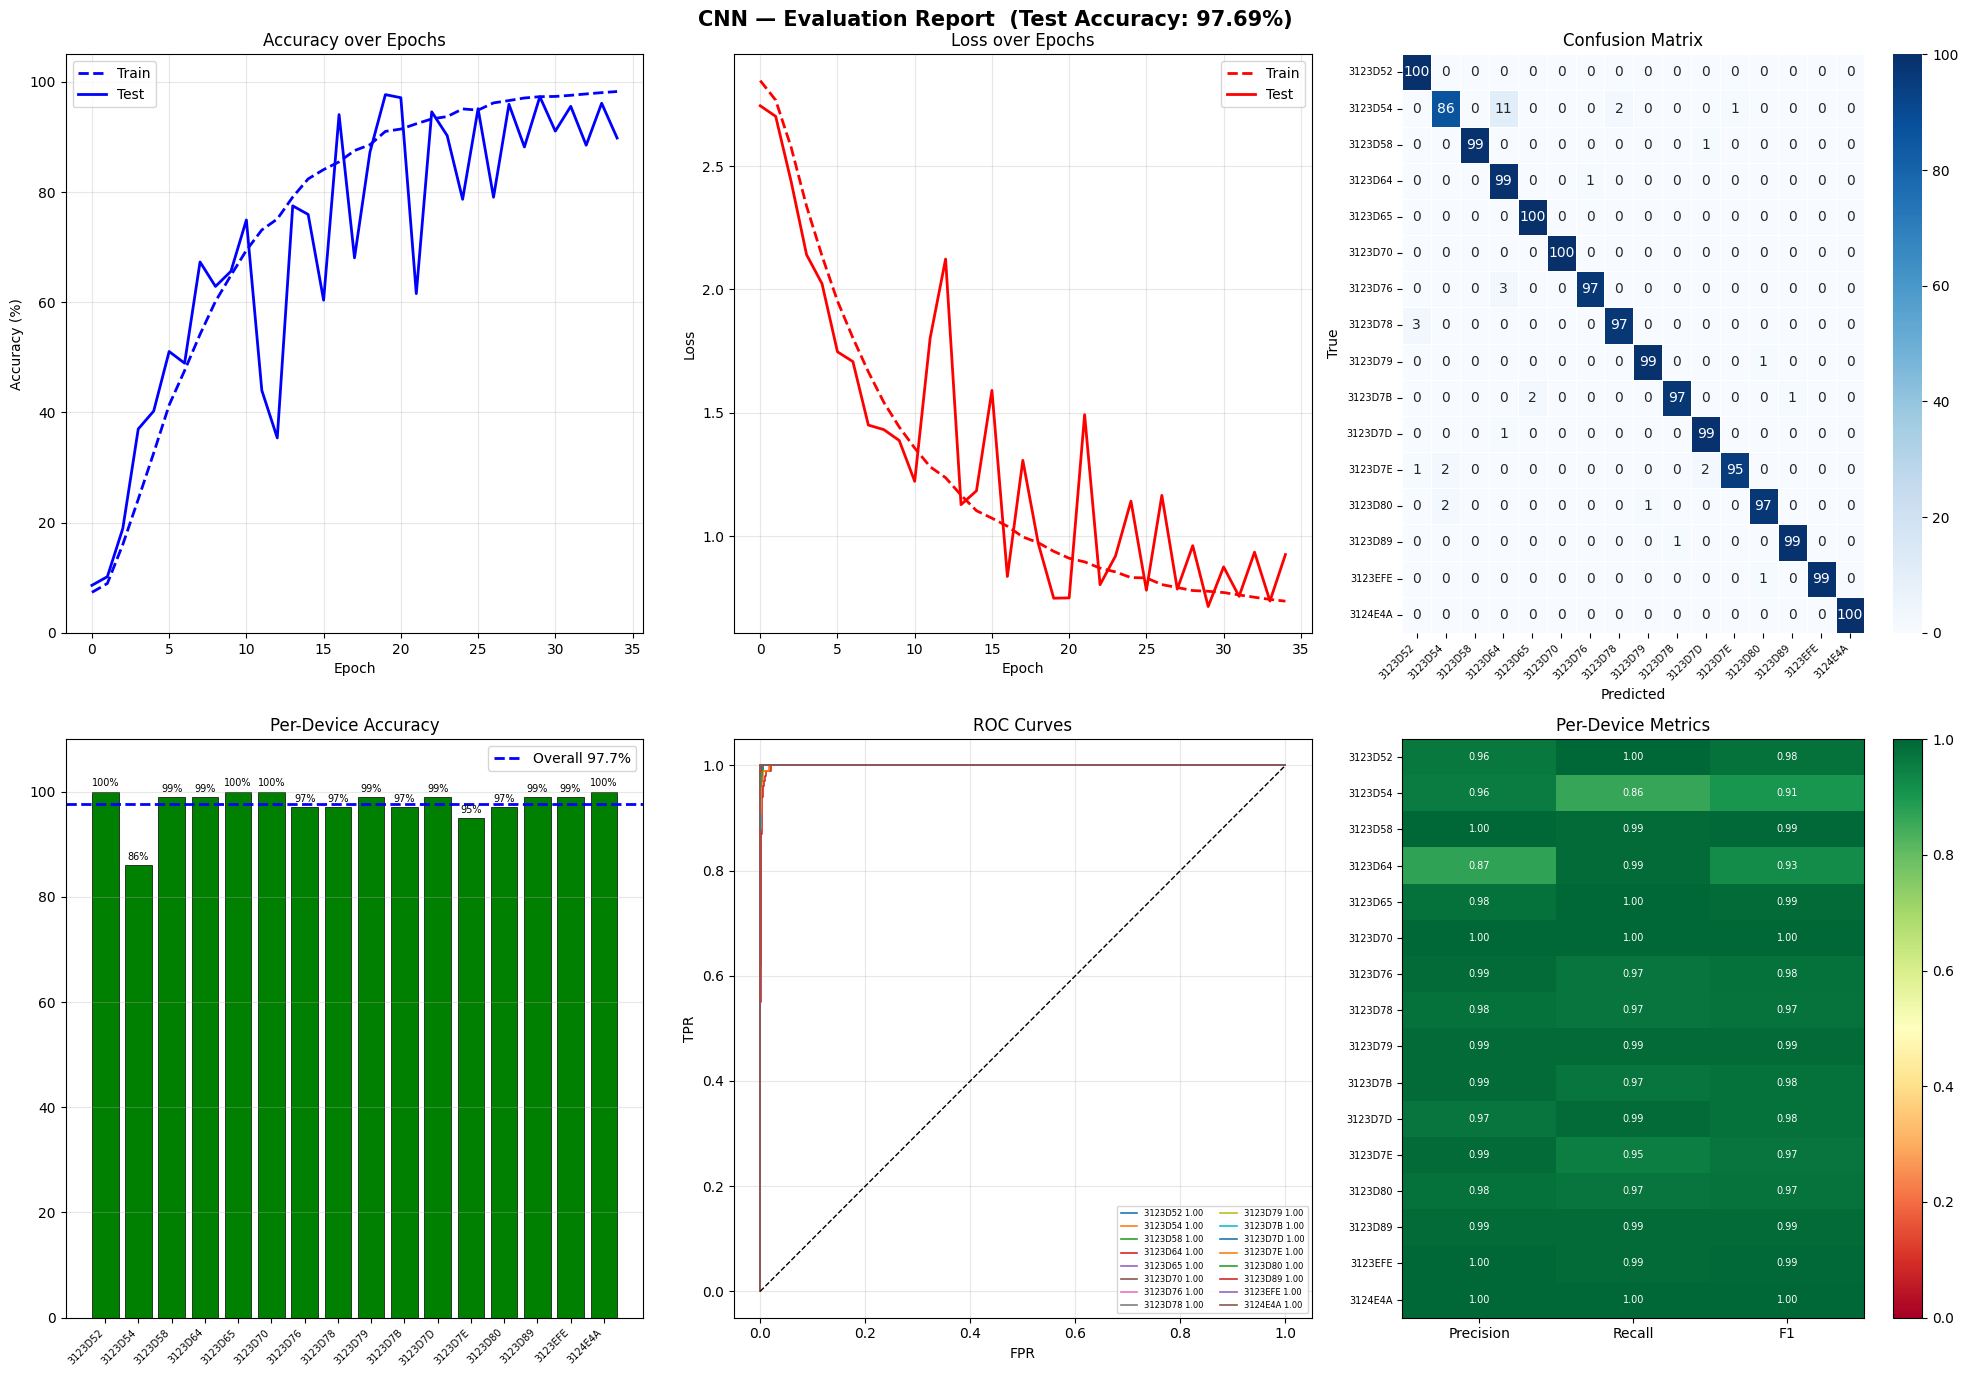

Saved → /content/drive/MyDrive/RF_Project/CNN_evaluation.png
              precision    recall  f1-score   support

     3123D52       0.96      1.00      0.98       100
     3123D54       0.96      0.86      0.91       100
     3123D58       1.00      0.99      0.99       100
     3123D64       0.87      0.99      0.93       100
     3123D65       0.98      1.00      0.99       100
     3123D70       1.00      1.00      1.00       100
     3123D76       0.99      0.97      0.98       100
     3123D78       0.98      0.97      0.97       100
     3123D79       0.99      0.99      0.99       100
     3123D7B       0.99      0.97      0.98       100
     3123D7D       0.97      0.99      0.98       100
     3123D7E       0.99      0.95      0.97       100
     3123D80       0.98      0.97      0.97       100
     3123D89       0.99      0.99      0.99       100
     3123EFE       1.00      0.99      0.99       100
     3124E4A       1.00      1.00      1.00       100

    accuracy       

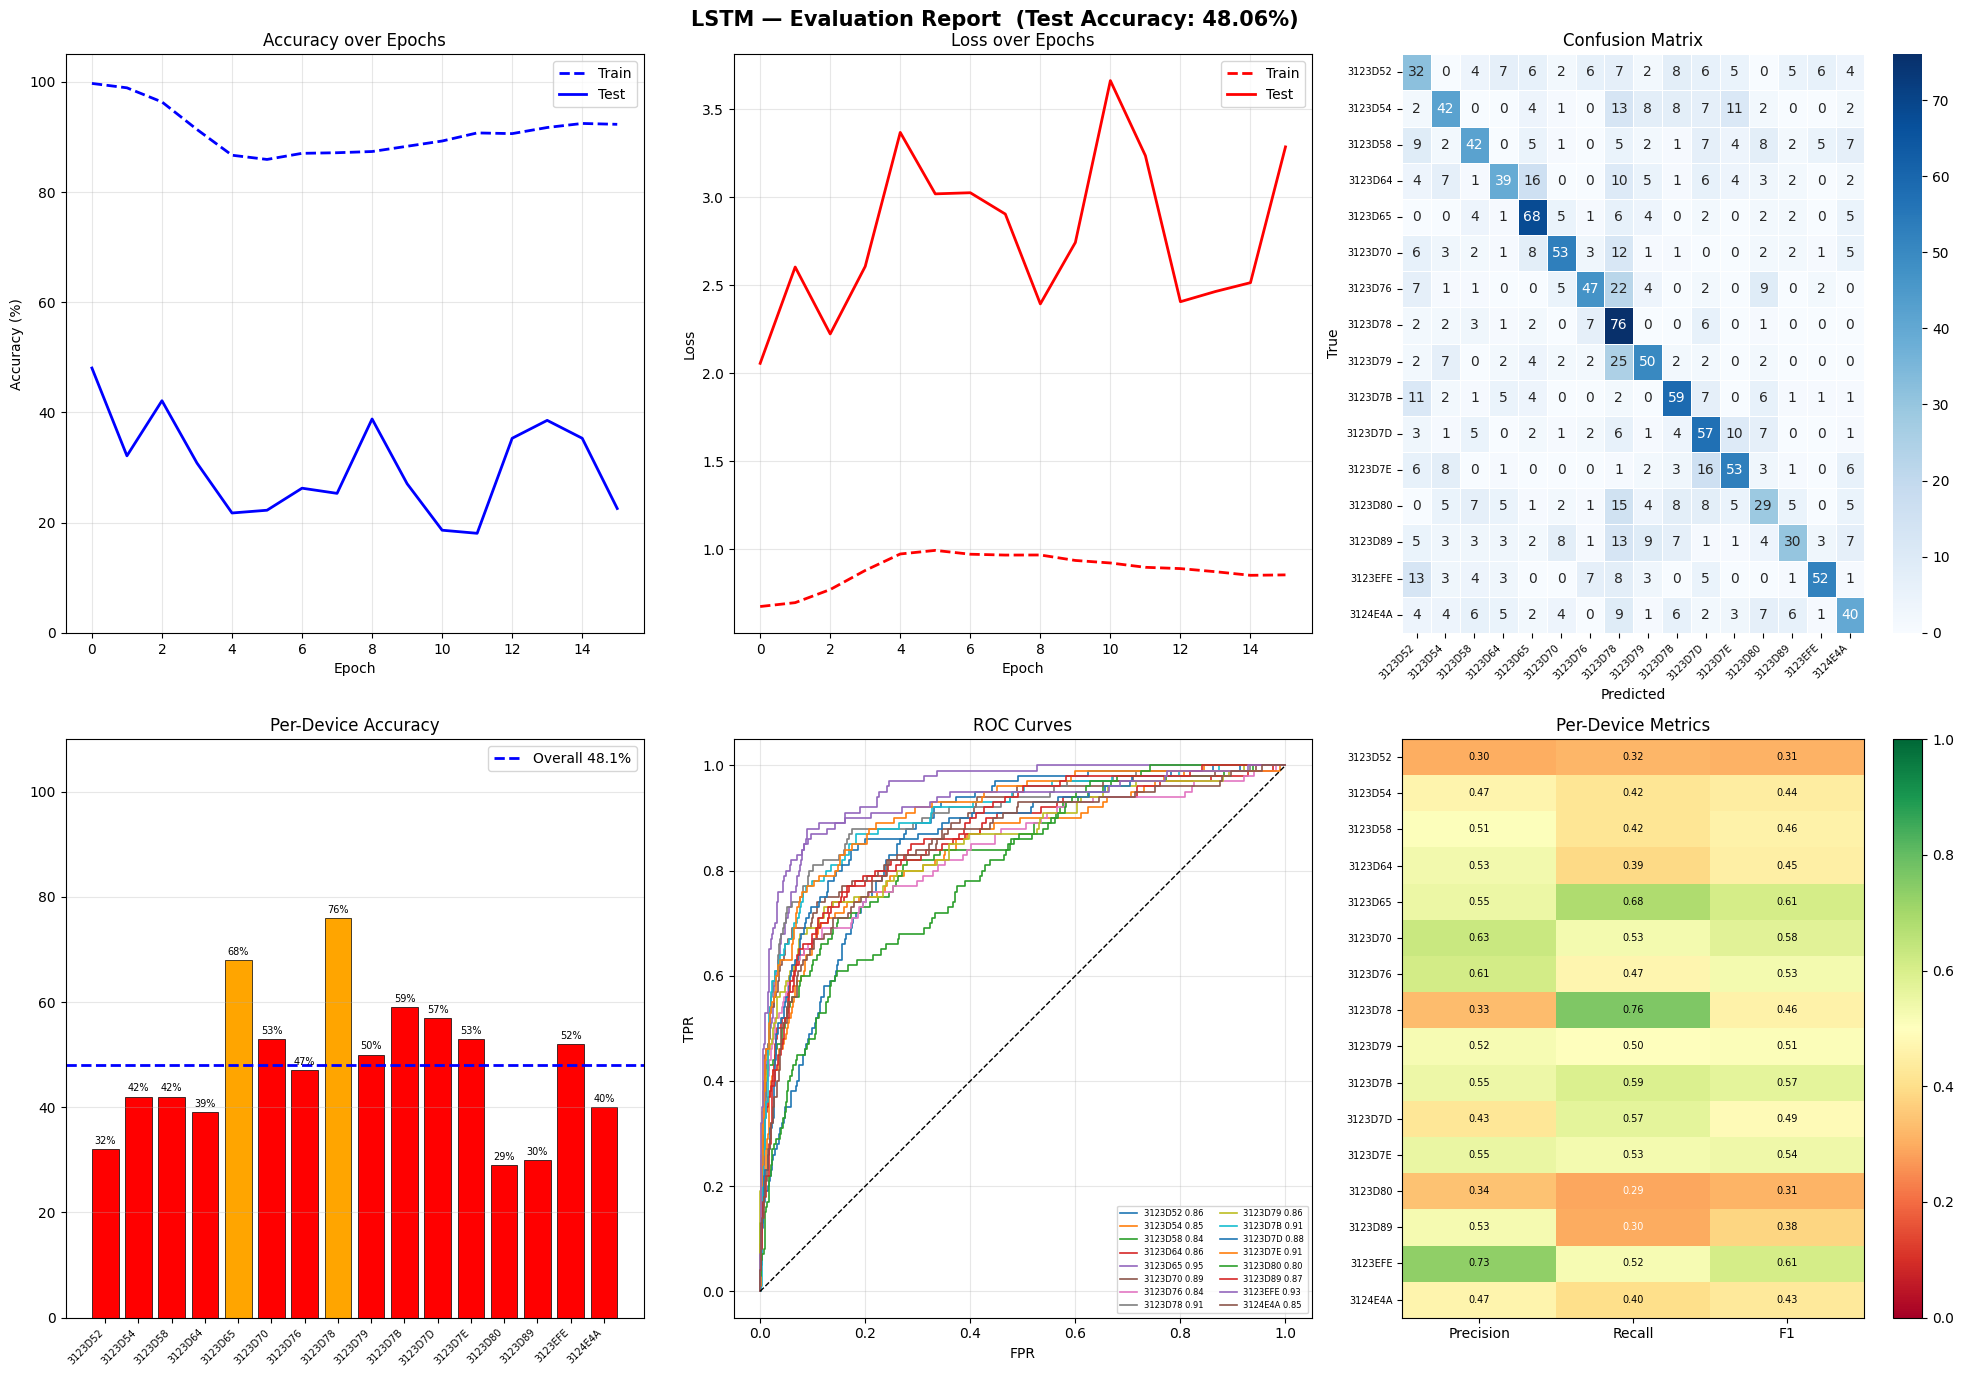

Saved → /content/drive/MyDrive/RF_Project/LSTM_evaluation.png
              precision    recall  f1-score   support

     3123D52       0.30      0.32      0.31       100
     3123D54       0.47      0.42      0.44       100
     3123D58       0.51      0.42      0.46       100
     3123D64       0.53      0.39      0.45       100
     3123D65       0.55      0.68      0.61       100
     3123D70       0.63      0.53      0.58       100
     3123D76       0.61      0.47      0.53       100
     3123D78       0.33      0.76      0.46       100
     3123D79       0.52      0.50      0.51       100
     3123D7B       0.55      0.59      0.57       100
     3123D7D       0.43      0.57      0.49       100
     3123D7E       0.55      0.53      0.54       100
     3123D80       0.34      0.29      0.31       100
     3123D89       0.53      0.30      0.38       100
     3123EFE       0.73      0.52      0.61       100
     3124E4A       0.47      0.40      0.43       100

    accuracy      

In [ ]:
def full_evaluation(model, test_loader, device_ids,
                    model_name, history):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for Xb, yb in test_loader:
            out  = model(Xb.to(device))
            prob = torch.softmax(out, dim=1)
            _, p = torch.max(out, 1)
            all_preds.extend(p.cpu().numpy())
            all_labels.extend(yb.numpy())
            all_probs.extend(prob.cpu().numpy())

    all_preds  = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs  = np.array(all_probs)
    acc        = 100 * np.mean(all_preds == all_labels)

    fig = plt.figure(figsize=(20, 14))
    fig.suptitle(f'{model_name} — Evaluation Report  '
                 f'(Test Accuracy: {acc:.2f}%)',
                 fontsize=15, fontweight='bold')

    # 1 — Accuracy curve
    ax = fig.add_subplot(2,3,1)
    ax.plot(history['train_acc'], 'b--', lw=2, label='Train')
    ax.plot(history['test_acc'],  'b-',  lw=2, label='Test')
    ax.set_title('Accuracy over Epochs')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy (%)')
    ax.legend(); ax.grid(True, alpha=0.3); ax.set_ylim(0,105)

    # 2 — Loss curve
    ax = fig.add_subplot(2,3,2)
    ax.plot(history['train_loss'], 'r--', lw=2, label='Train')
    ax.plot(history['test_loss'],  'r-',  lw=2, label='Test')
    ax.set_title('Loss over Epochs')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(True, alpha=0.3)

    # 3 — Confusion matrix
    ax  = fig.add_subplot(2,3,3)
    cm  = confusion_matrix(all_labels, all_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=device_ids,
                yticklabels=device_ids, ax=ax, linewidths=0.5)
    ax.set_title(f'Confusion Matrix')
    ax.set_ylabel('True'); ax.set_xlabel('Predicted')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=7)
    plt.setp(ax.get_yticklabels(), rotation=0,  fontsize=7)

    # 4 — Per-class accuracy
    ax  = fig.add_subplot(2,3,4)
    pca = [100*(all_preds[all_labels==i]==i).mean()
           if (all_labels==i).sum()>0 else 0
           for i in range(len(device_ids))]
    cols = ['green' if a>=80 else 'orange' if a>=60 else 'red'
            for a in pca]
    bars = ax.bar(device_ids, pca, color=cols,
                  edgecolor='black', linewidth=0.5)
    ax.axhline(acc, color='blue', linestyle='--', lw=2,
               label=f'Overall {acc:.1f}%')
    ax.set_title('Per-Device Accuracy')
    ax.set_ylim(0,110); ax.legend(); ax.grid(True,alpha=0.3,axis='y')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=7)
    for b,v in zip(bars,pca):
        ax.text(b.get_x()+b.get_width()/2, v+1,
                f'{v:.0f}%', ha='center', fontsize=7)

    # 5 — ROC curves
    ax    = fig.add_subplot(2,3,5)
    y_bin = label_binarize(all_labels,
                           classes=list(range(len(device_ids))))
    for i, dev in enumerate(device_ids):
        fpr, tpr, _ = roc_curve(y_bin[:,i], all_probs[:,i])
        ax.plot(fpr, tpr, lw=1.2, label=f'{dev} {auc(fpr,tpr):.2f}')
    ax.plot([0,1],[0,1],'k--',lw=1)
    ax.set_title('ROC Curves')
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.legend(loc='lower right', fontsize=6, ncol=2)
    ax.grid(True, alpha=0.3)

    # 6 — F1 heatmap
    ax  = fig.add_subplot(2,3,6)
    rep = classification_report(all_labels, all_preds,
                                target_names=device_ids,
                                output_dict=True)
    mdf = np.array([[rep[d]['precision'],
                     rep[d]['recall'],
                     rep[d]['f1-score']]
                    for d in device_ids])
    im  = ax.imshow(mdf, aspect='auto',
                    cmap='RdYlGn', vmin=0, vmax=1)
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(['Precision','Recall','F1'])
    ax.set_yticks(range(len(device_ids)))
    ax.set_yticklabels(device_ids, fontsize=7)
    ax.set_title('Per-Device Metrics')
    plt.colorbar(im, ax=ax)
    for i in range(len(device_ids)):
        for j,v in enumerate(mdf[i]):
            ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                    fontsize=7,
                    color='black' if 0.3<v<0.8 else 'white')

    plt.tight_layout()
    path = SAVE_PATH + f'{model_name}_evaluation.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved → {path}")
    print(classification_report(all_labels, all_preds,
                                target_names=device_ids))
    return acc, all_preds, all_labels, all_probs

print("Evaluating CNN...")
cnn_acc, cnn_preds, cnn_labels, cnn_probs = full_evaluation(
    cnn_model, test_loader_cnn, device_ids, 'CNN', cnn_history)

print("\nEvaluating LSTM...")
lstm_acc, lstm_preds, lstm_labels, lstm_probs = full_evaluation(
    lstm_model, test_loader_lstm, device_ids, 'LSTM', lstm_history)

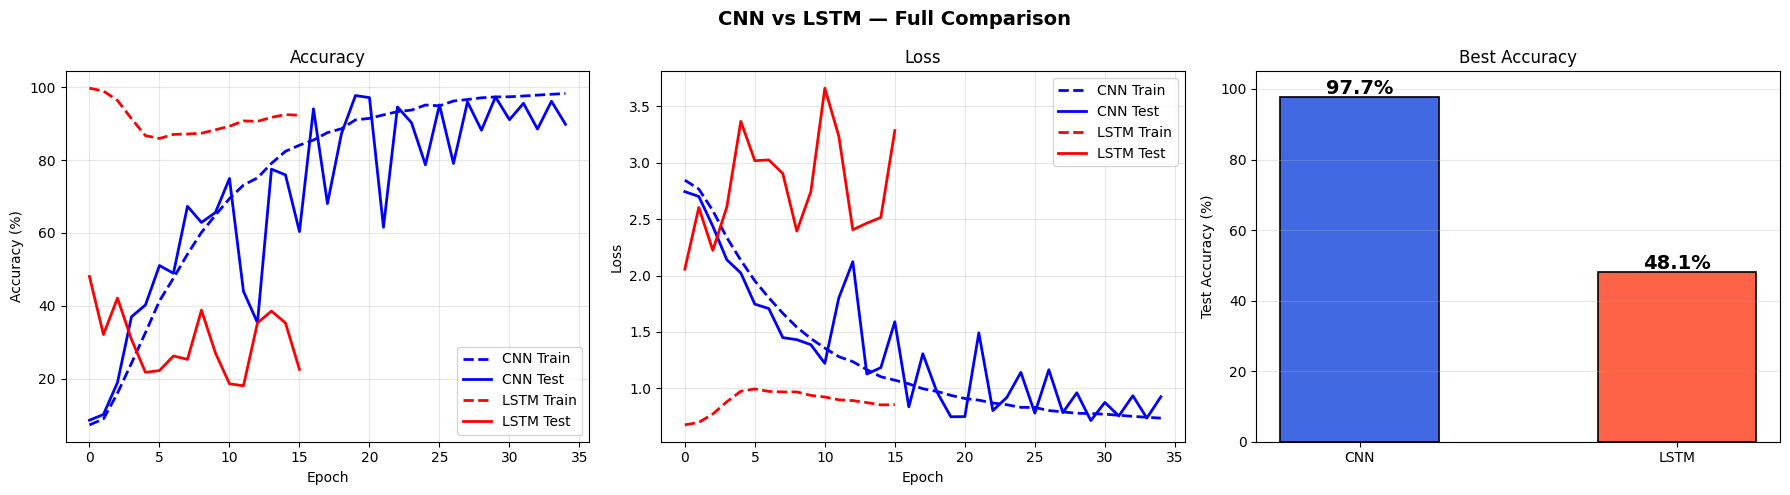

Saved → /content/drive/MyDrive/RF_Project/CNN_vs_LSTM_comparison.png

CNN  best: 97.69%
LSTM best: 48.06%


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('CNN vs LSTM — Full Comparison', fontsize=14, fontweight='bold')

axes[0].plot(cnn_history['train_acc'],  'b--', lw=2, label='CNN Train')
axes[0].plot(cnn_history['test_acc'],   'b-',  lw=2, label='CNN Test')
axes[0].plot(lstm_history['train_acc'], 'r--', lw=2, label='LSTM Train')
axes[0].plot(lstm_history['test_acc'],  'r-',  lw=2, label='LSTM Test')
axes[0].set_title('Accuracy'); axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy (%)'); axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(cnn_history['train_loss'],  'b--', lw=2, label='CNN Train')
axes[1].plot(cnn_history['test_loss'],   'b-',  lw=2, label='CNN Test')
axes[1].plot(lstm_history['train_loss'], 'r--', lw=2, label='LSTM Train')
axes[1].plot(lstm_history['test_loss'],  'r-',  lw=2, label='LSTM Test')
axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss'); axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].bar(['CNN', 'LSTM'], [cnn_best_acc, lstm_best_acc],
            color=['royalblue','tomato'],
            edgecolor='black', linewidth=1.2, width=0.5)
axes[2].set_title('Best Accuracy')
axes[2].set_ylabel('Test Accuracy (%)')
axes[2].set_ylim(0, 105)
axes[2].grid(True, alpha=0.3, axis='y')
for i, (n,v) in enumerate([('CNN',cnn_best_acc),('LSTM',lstm_best_acc)]):
    axes[2].text(i, v+1, f'{v:.1f}%',
                 ha='center', fontsize=14, fontweight='bold')

plt.tight_layout()
path = SAVE_PATH + 'CNN_vs_LSTM_comparison.png'
plt.savefig(path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {path}")
print(f"\nCNN  best: {cnn_best_acc:.2f}%")
print(f"LSTM best: {lstm_best_acc:.2f}%")

Running SNR Robustness Experiment (using real 4096-sample chunks)...

     SNR |        CNN |       LSTM
------------------------------------
      30 |      98.0% |      36.6%
      20 |      60.6% |      35.9%
      10 |      15.2% |      28.3%
       0 |       6.6% |       8.9%
     -10 |       7.9% |       6.5%


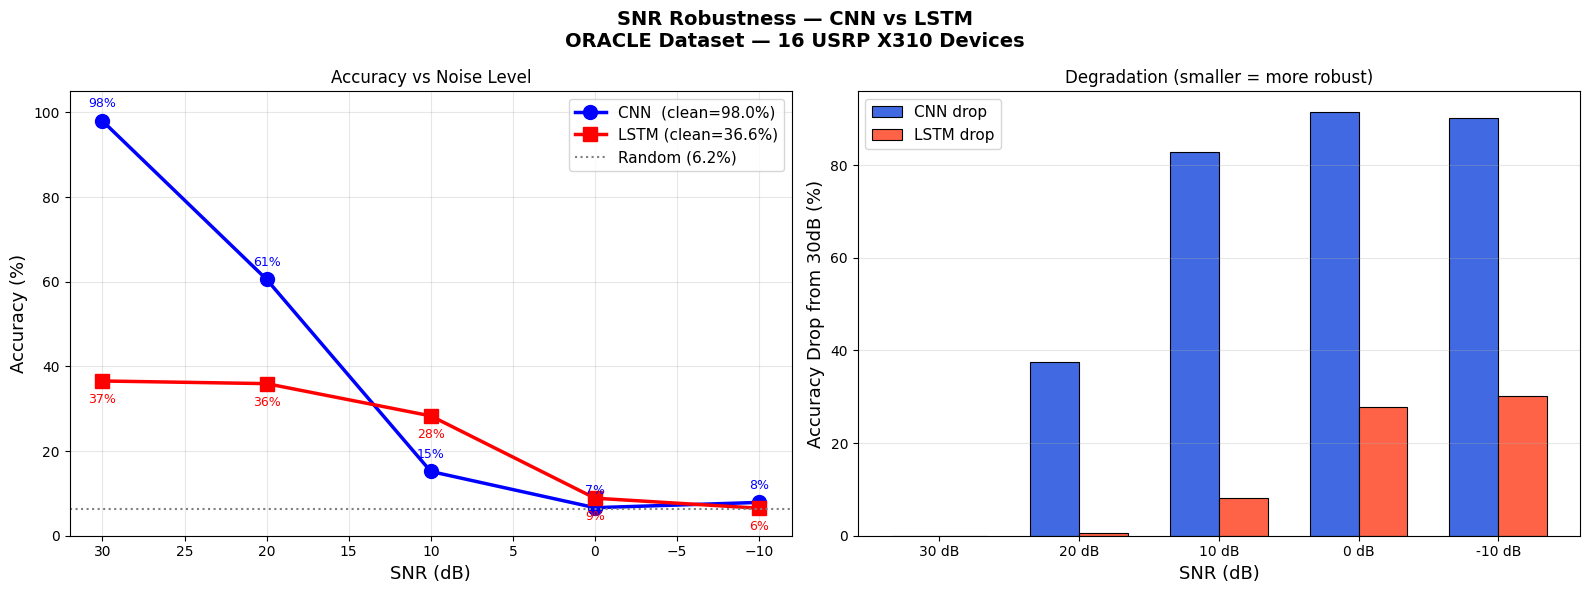


Saved → /content/drive/MyDrive/RF_Project/SNR_robustness_v2.png

   SNR |      CNN |     LSTM |   Better
------------------------------------------------
    30 |    98.0% |    36.6% |      CNN
    20 |    60.6% |    35.9% |      CNN
    10 |    15.2% |    28.3% |     LSTM
     0 |     6.6% |     8.9% |     LSTM
   -10 |     7.9% |     6.5% |      CNN
------------------------------------------------
   Avg |    37.6% |    23.2%


In [ ]:
def snr_robustness_test(cnn_model, lstm_model,
                        X_test_raw_iq,   # (N, 4096) complex — real chunks
                        X_test_lstm_iq,  # (N, 4096, 2) float — same chunks
                        y_test,
                        snr_levels=[30, 20, 10, 0, -10]):
    """
    SNR robustness test using real 4096-sample IQ chunks.
    No tiling needed — each sample is already the correct length.
    """

    def add_noise(iq_c, snr_db):
        """Add AWGN noise at given SNR to complex IQ."""
        pwr   = np.mean(np.abs(iq_c) ** 2)
        pwr   = max(float(pwr), 1e-10)
        n_pwr = pwr / (10 ** (snr_db / 10.0))
        noise = np.sqrt(n_pwr / 2.0) * (
            np.random.randn(len(iq_c)) +
            1j * np.random.randn(len(iq_c))
        )
        return (iq_c + noise).astype(np.complex128)

    cnn_model.eval()
    lstm_model.eval()
    cnn_accs, lstm_accs = [], []
    BS = 32

    print(f"\n{'SNR':>8} | {'CNN':>10} | {'LSTM':>10}")
    print("-" * 36)

    for snr in snr_levels:
        cnn_c = lstm_c = 0

        for i in range(0, len(X_test_raw_iq), BS):
            raw_batch  = X_test_raw_iq[i  : i+BS]   # (B, 4096) complex
            lstm_batch = X_test_lstm_iq[i : i+BS]   # (B, 4096, 2) float
            yb         = y_test[i : i+BS]

            # ── CNN ───────────────────────────────────────────────────────────
            # Add noise to raw complex IQ → make spectrogram → classify
            specs = []
            for iq_c in raw_batch:
                iq_noisy = add_noise(iq_c.astype(np.complex128), snr)
                specs.append(iq_to_spectrogram(iq_noisy))

            specs_t = torch.tensor(
                np.array(specs)[:, np.newaxis, :, :],
                dtype=torch.float32
            ).to(device)

            with torch.no_grad():
                _, p = torch.max(cnn_model(specs_t), 1)
            cnn_c += (p.cpu().numpy() == yb).sum()

            # ── LSTM ──────────────────────────────────────────────────────────
            # Add noise to IQ float array → normalize → classify
            noisy_seqs = []
            for iq_2d in lstm_batch:
                # Reconstruct complex, add noise, convert back
                iq_c     = iq_2d[:, 0].astype(np.float64) + \
                           1j * iq_2d[:, 1].astype(np.float64)
                iq_noisy = add_noise(iq_c, snr)
                arr      = np.stack([iq_noisy.real,
                                     iq_noisy.imag],
                                    axis=1).astype(np.float32)
                # Per-sample normalization
                arr      = (arr - arr.mean(axis=0, keepdims=True)) / \
                           (arr.std(axis=0, keepdims=True) + 1e-8)
                noisy_seqs.append(arr)

            iq_t = torch.tensor(np.array(noisy_seqs),
                                dtype=torch.float32).to(device)

            with torch.no_grad():
                _, p = torch.max(lstm_model(iq_t), 1)
            lstm_c += (p.cpu().numpy() == yb).sum()

        ca = 100.0 * cnn_c  / len(y_test)
        la = 100.0 * lstm_c / len(y_test)
        cnn_accs.append(ca)
        lstm_accs.append(la)
        print(f"{snr:>8} | {ca:>9.1f}% | {la:>9.1f}%")

    # ── Plot ──────────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle('SNR Robustness — CNN vs LSTM\n'
                 'ORACLE Dataset — 16 USRP X310 Devices',
                 fontsize=14, fontweight='bold')

    axes[0].plot(snr_levels, cnn_accs,  'bo-', lw=2.5, ms=10,
                 label=f'CNN  (clean={cnn_accs[0]:.1f}%)')
    axes[0].plot(snr_levels, lstm_accs, 'rs-', lw=2.5, ms=10,
                 label=f'LSTM (clean={lstm_accs[0]:.1f}%)')
    axes[0].axhline(100.0/NUM_CLASSES, color='gray',
                    linestyle=':', lw=1.5,
                    label=f'Random ({100/NUM_CLASSES:.1f}%)')
    axes[0].set_xlabel('SNR (dB)', fontsize=13)
    axes[0].set_ylabel('Accuracy (%)', fontsize=13)
    axes[0].set_title('Accuracy vs Noise Level')
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)
    axes[0].invert_xaxis()
    axes[0].set_ylim(0, 105)
    for x, ya, yb in zip(snr_levels, cnn_accs, lstm_accs):
        axes[0].annotate(f'{ya:.0f}%', (x, ya),
                         textcoords='offset points', xytext=(0, 10),
                         ha='center', fontsize=9, color='blue')
        axes[0].annotate(f'{yb:.0f}%', (x, yb),
                         textcoords='offset points', xytext=(0, -16),
                         ha='center', fontsize=9, color='red')

    cnn_drop  = [cnn_accs[0]  - a for a in cnn_accs]
    lstm_drop = [lstm_accs[0] - a for a in lstm_accs]
    xp = np.arange(len(snr_levels))
    w  = 0.35
    axes[1].bar(xp - w/2, cnn_drop,  w, label='CNN drop',
                color='royalblue', edgecolor='black', lw=0.8)
    axes[1].bar(xp + w/2, lstm_drop, w, label='LSTM drop',
                color='tomato',    edgecolor='black', lw=0.8)
    axes[1].set_xticks(xp)
    axes[1].set_xticklabels([f'{s} dB' for s in snr_levels])
    axes[1].set_xlabel('SNR (dB)', fontsize=13)
    axes[1].set_ylabel('Accuracy Drop from 30dB (%)', fontsize=13)
    axes[1].set_title('Degradation (smaller = more robust)')
    axes[1].legend(fontsize=11)
    axes[1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    path = SAVE_PATH + 'SNR_robustness_v2.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"\nSaved → {path}")

    print(f"\n{'='*48}")
    print(f"{'SNR':>6} | {'CNN':>8} | {'LSTM':>8} | {'Better':>8}")
    print("-" * 48)
    for s, ca, la in zip(snr_levels, cnn_accs, lstm_accs):
        print(f"{s:>6} | {ca:>7.1f}% | {la:>7.1f}% | "
              f"{'CNN' if ca >= la else 'LSTM':>8}")
    print("-" * 48)
    print(f"{'Avg':>6} | {np.mean(cnn_accs):>7.1f}% | "
          f"{np.mean(lstm_accs):>7.1f}%")

    return cnn_accs, lstm_accs


print("Running SNR Robustness Experiment (using real 4096-sample chunks)...")
cnn_snr_accs, lstm_snr_accs = snr_robustness_test(
    cnn_model      = cnn_model,
    lstm_model     = lstm_model,
    X_test_raw_iq  = X_test_raw,
    X_test_lstm_iq = X_test_lstm,
    y_test         = y_test,
    snr_levels     = [30, 20, 10, 0, -10]
)